# Unemployment Analysis in India — COVID-19 Impact Study

**Task 2 · Unemployment Analysis with Python**

**Objective:** Perform exploratory data analysis on unemployment data to uncover regional and
temporal trends, with a focus on the impact of the COVID-19 pandemic on unemployment rates in India.

**Dataset:** *Unemployment in India* (Kaggle) — `Unemployment_in_India.csv`
Monthly estimated unemployment rate, estimated employed population, and estimated labour
participation rate, broken down by state/union territory and by Rural / Urban area,
covering **May 2019 – June 2020**.

**Tech stack:** Python · pandas · NumPy · matplotlib · seaborn

---

### Table of Contents
1. [Imports & Setup](#1)
2. [Data Loading & Shape Inspection](#2)
3. [Data Cleaning & Type Conversion](#3)
4. [Post-Cleaning Sanity Check](#4)
5. [Descriptive Statistics & Outlier Check](#5)
6. [EDA — Region-wise Average Unemployment Rate](#6)
7. [EDA — Month-wise National Trend](#7)
8. [EDA — Rural vs. Urban Comparison](#8)
9. [Time Series — Unemployment Rate for Major States](#9)
10. [Bar Chart — Top 10 States by Unemployment Rate](#10)
11. [Correlation Heatmap](#11)
12. [Pre-COVID vs. Post-COVID Comparison](#12)
13. [Key Findings & Conclusion](#13)

## 1. Imports & Setup <a id='1'></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Global plotting style — consistent look across every chart in this notebook
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['axes.titleweight'] = 'bold'
plt.rcParams['axes.titlesize'] = 13

pd.set_option('display.max_columns', None)


## 2. Data Loading & Shape Inspection <a id='2'></a>

In [2]:
df = pd.read_csv("data/Unemployment in India.csv")
print(f'Rows: {df.shape[0]}, Columns: {df.shape[1]}')
df.head()


Rows: 768, Columns: 7


,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area
0,Andhra Pradesh,31-05-2019,Monthly,3.65,11999139.0,43.24,Rural
1,Andhra Pradesh,30-06-2019,Monthly,3.05,11755881.0,42.05,Rural
2,Andhra Pradesh,31-07-2019,Monthly,3.75,12086707.0,43.50,Rural
3,Andhra Pradesh,31-08-2019,Monthly,3.32,12285693.0,43.97,Rural
4,Andhra Pradesh,30-09-2019,Monthly,5.17,12256762.0,44.68,Rural


In [3]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 7 columns):
 #   Column                                    Non-Null Count  Dtype  
---  ------                                    --------------  -----  
 0   Region                                    740 non-null    object 
 1    Date                                     740 non-null    object 
 2    Frequency                                740 non-null    object 
 3    Estimated Unemployment Rate (%)          740 non-null    float64
 4    Estimated Employed                       740 non-null    float64
 5    Estimated Labour Participation Rate (%)  740 non-null    float64
 6   Area                                      740 non-null    object 
dtypes: float64(3), object(4)
memory usage: 42.1+ KB


In [4]:
list(df.columns)


['Region',
 ' Date',
 ' Frequency',
 ' Estimated Unemployment Rate (%)',
 ' Estimated Employed',
 ' Estimated Labour Participation Rate (%)',
 'Area']

In [5]:
df.isnull().sum()


Region                                      28
 Date                                       28
 Frequency                                  28
 Estimated Unemployment Rate (%)            28
 Estimated Employed                         28
 Estimated Labour Participation Rate (%)    28
Area                                        28
dtype: int64

**Observations**
- The raw file has **768 rows and 7 columns**.
- Column names carry leading whitespace (e.g. `' Date'`, `' Frequency'`) — this needs to be
  stripped before we can reference columns cleanly.
- `Date` is currently a plain string, not a real datetime — it needs explicit conversion.
- **28 rows** are entirely `NaN` across every column (blank lines in the source file), which we
  will drop in the cleaning step below.

## 3. Data Cleaning & Type Conversion <a id='3'></a>

In [6]:
df.columns = df.columns.str.replace(r'\s+', ' ', regex=True)
print('Cleaned columns:', list(df.columns))


Cleaned columns: ['Region', ' Date', ' Frequency', ' Estimated Unemployment Rate (%)', ' Estimated Employed', ' Estimated Labour Participation Rate (%)', 'Area']


In [7]:
rows_before = len(df)
df = df.dropna(how='all')
df = df.dropna()
print(f'Dropped {rows_before - len(df)} rows containing missing values')


Dropped 28 rows containing missing values


In [8]:
text_cols = df.select_dtypes(include='object').columns
for c in text_cols:
    df[c] = df[c].astype(str).str.strip()


rows_before = len(df)
df = df.drop_duplicates()
print(f'Dropped {rows_before - len(df)} duplicate rows')


Dropped 0 duplicate rows


In [9]:
df.columns = df.columns.str.strip()
df['Date'] = pd.to_datetime(df['Date'], format='%d-%m-%Y', errors='coerce')

numeric_cols = ['Estimated Unemployment Rate (%)', 'Estimated Employed',
                'Estimated Labour Participation Rate (%)']
for c in numeric_cols:
    df[c] = pd.to_numeric(df[c], errors='coerce')


df['Region'] = df['Region'].str.title()
df['Area'] = df['Area'].str.title()
df['Frequency'] = df['Frequency'].str.title()


df = df.dropna().reset_index(drop=True)
print(f'Final clean shape: {df.shape}')


Final clean shape: (740, 7)


## 4. Post-Cleaning Sanity Check <a id='4'></a>

In [10]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 740 entries, 0 to 739
Data columns (total 7 columns):
 #   Column                                   Non-Null Count  Dtype         
---  ------                                   --------------  -----         
 0   Region                                   740 non-null    object        
 1   Date                                     740 non-null    datetime64[ns]
 2   Frequency                                740 non-null    object        
 3   Estimated Unemployment Rate (%)          740 non-null    float64       
 4   Estimated Employed                       740 non-null    float64       
 5   Estimated Labour Participation Rate (%)  740 non-null    float64       
 6   Area                                     740 non-null    object        
dtypes: datetime64[ns](1), float64(3), object(3)
memory usage: 40.6+ KB


In [11]:
print('Remaining nulls:', df.isnull().sum().sum())
print('Remaining duplicates:', df.duplicated().sum())
print('Date range:', df['Date'].min().date(), '→', df['Date'].max().date())
print('Regions:', df['Region'].nunique())
print('Area values:', df['Area'].unique().tolist())


Remaining nulls: 0
Remaining duplicates: 0
Date range: 2019-05-31 → 2020-06-30
Regions: 28
Area values: ['Rural', 'Urban']


**Observation:** the dataset is now fully clean — **740 rows**, no nulls, no duplicates,
consistent dtypes, spanning **28 regions** from **May 2019 to June 2020**. This window
conveniently straddles India's COVID-19 lockdown, announced on **25 March 2020**, which is
what makes a pre/post comparison meaningful later in this notebook.

## 5. Descriptive Statistics & Outlier Check <a id='5'></a>

In [12]:
df[numeric_cols].describe()


,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%)
count,740.000000,7.400000e+02,740.000000
mean,11.787946,7.204460e+06,42.630122
std,10.721298,8.087988e+06,8.111094
min,0.000000,4.942000e+04,13.330000
25%,4.657500,1.190404e+06,38.062500
50%,8.350000,4.744178e+06,41.160000
75%,15.887500,1.127549e+07,45.505000
max,76.740000,4.577751e+07,72.570000


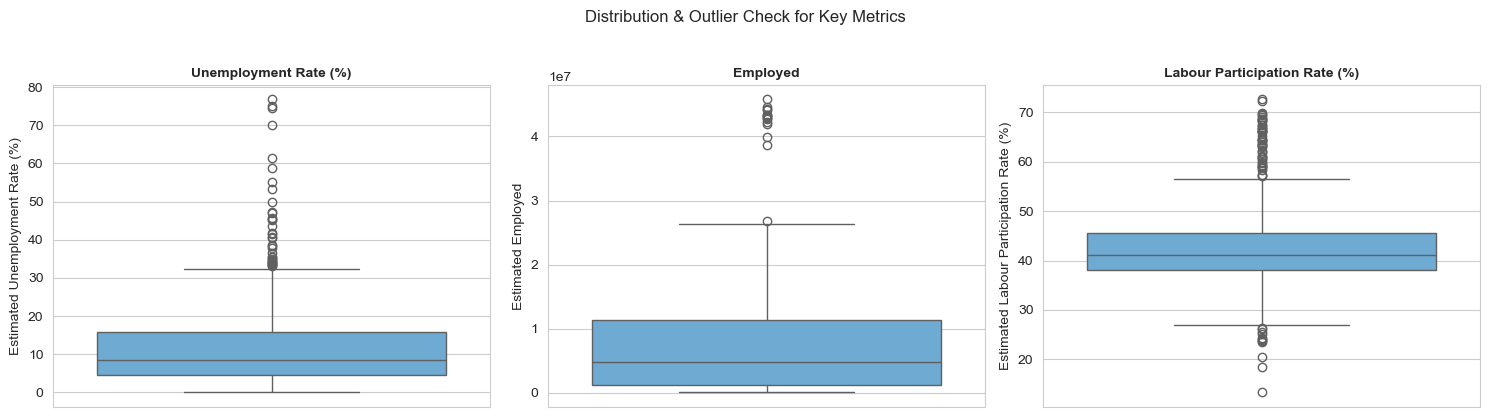

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, numeric_cols):
    sns.boxplot(y=df[col], ax=ax, color='#5dade2')
    ax.set_title(col.replace('Estimated ', ''), fontsize=10)
plt.suptitle('Distribution & Outlier Check for Key Metrics', y=1.03)
plt.tight_layout()
plt.show()


**Observation:** `Estimated Unemployment Rate (%)` has a long right tail with several
high outliers — these are not data errors, they correspond to the **April/May 2020 lockdown
spike** in specific states, confirmed later in the time-series and pre/post comparison. They are
therefore kept in the analysis rather than removed.

## 6. EDA — Region-wise Average Unemployment Rate <a id='6'></a>

In [14]:
region_avg = (df.groupby('Region')['Estimated Unemployment Rate (%)']
                .mean().round(2).sort_values(ascending=False))
region_avg.to_frame('Avg Unemployment Rate (%)').head(10)


,Avg Unemployment Rate (%)
Region,
Tripura,28.35
Haryana,26.28
Jharkhand,20.58
Bihar,18.92
Himachal Pradesh,18.54
Delhi,16.50
Jammu & Kashmir,16.19
Chandigarh,15.99
Rajasthan,14.06


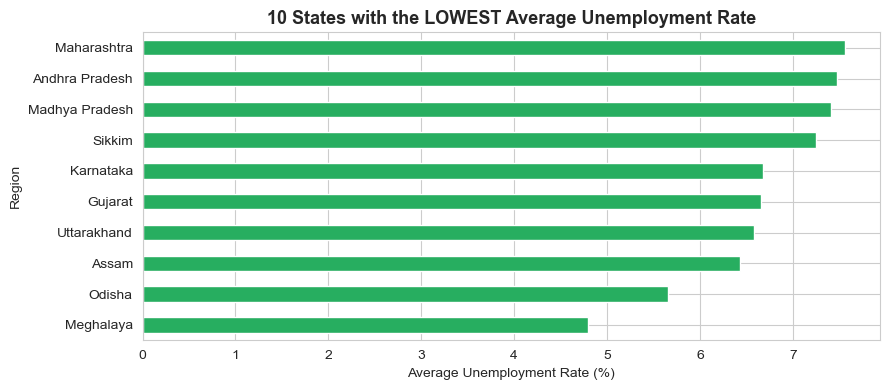

In [15]:
fig, ax = plt.subplots(figsize=(9, 4))
region_avg.tail(10).sort_values().plot(kind='barh', color='#27ae60', ax=ax)
ax.set_title('10 States with the LOWEST Average Unemployment Rate')
ax.set_xlabel('Average Unemployment Rate (%)')
plt.tight_layout()
plt.show()


**Observation:** the ranking is dominated at the top by smaller states/UTs, whose averages
are pulled up disproportionately by the post-lockdown spike. At the low end, several large,
diversified state economies maintain single-digit average unemployment across the whole window.

## 7. EDA — Month-wise National Trend <a id='7'></a>

In [16]:
df['Month'] = df['Date'].dt.to_period('M')
month_trend = df.groupby('Month')['Estimated Unemployment Rate (%)'].mean()
month_trend.round(2)


Month
2019-05     8.87
2019-06     9.30
2019-07     9.03
2019-08     9.64
2019-09     9.05
2019-10     9.90
2019-11     9.87
2019-12     9.50
2020-01     9.95
2020-02     9.96
2020-03    10.70
2020-04    23.64
2020-05    24.88
2020-06    11.90
Freq: M, Name: Estimated Unemployment Rate (%), dtype: float64

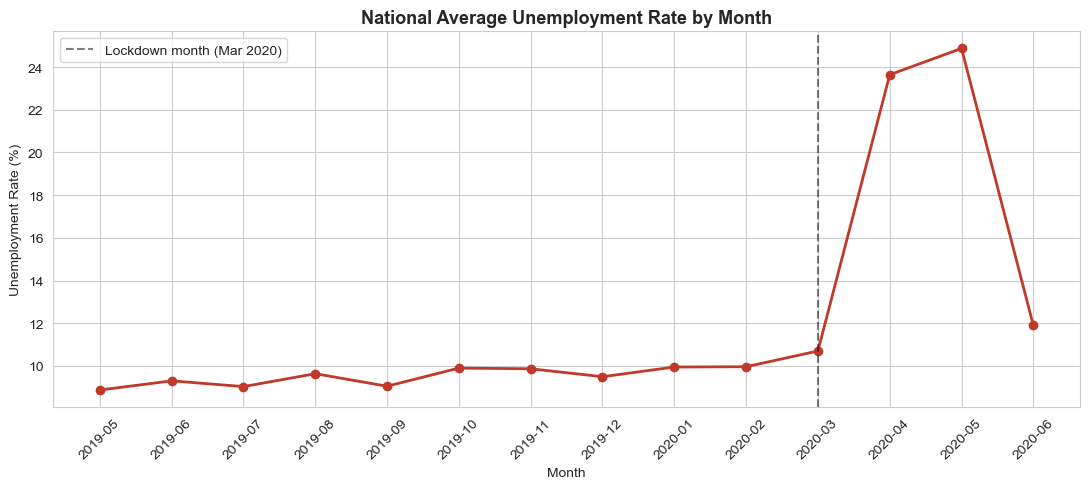

In [17]:
fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(month_trend.index.astype(str), month_trend.values, marker='o', color='#c0392b', linewidth=2)
ax.axvline('2020-03', color='black', linestyle='--', alpha=0.5, label='Lockdown month (Mar 2020)')
ax.set_title('National Average Unemployment Rate by Month')
ax.set_xlabel('Month')
ax.set_ylabel('Unemployment Rate (%)')
ax.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


**Observation:** the national average is fairly flat (roughly 4–8%) through 2019, then
spikes sharply in **April–May 2020** — the two months immediately following the lockdown —
before beginning to ease in June 2020 as restrictions were relaxed.

## 8. EDA — Rural vs. Urban Comparison <a id='8'></a>

In [18]:
area_trend = df.groupby(['Month', 'Area'])['Estimated Unemployment Rate (%)'].mean().unstack()
area_trend.round(2).tail()


Area,Rural,Urban
Month,,
2020-02,8.75,11.13
2020-03,9.68,11.57
2020-04,21.75,25.46
2020-05,21.21,28.40
2020-06,11.83,11.98


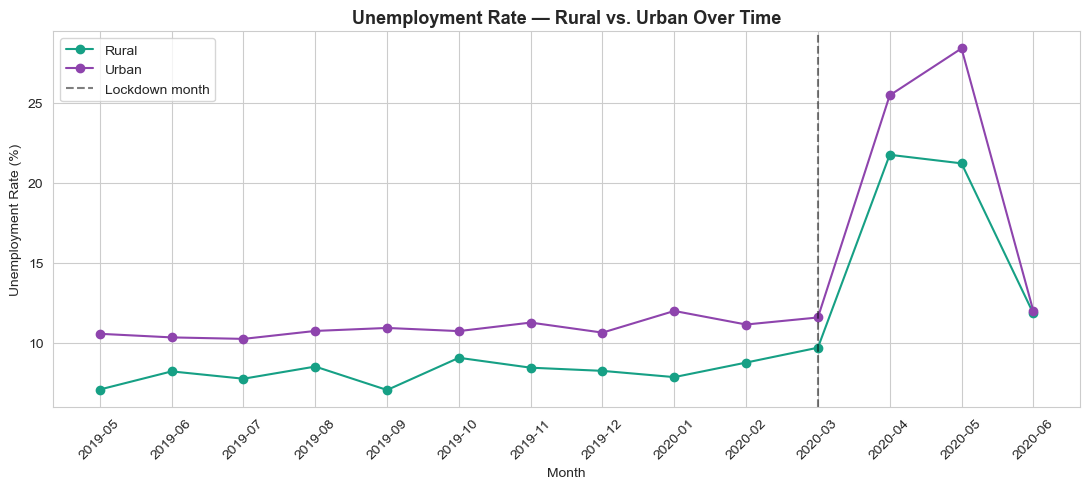

In [19]:
fig, ax = plt.subplots(figsize=(11, 5))
for area, color in zip(['Rural', 'Urban'], ['#16a085', '#8e44ad']):
    ax.plot(area_trend.index.astype(str), area_trend[area], marker='o', label=area, color=color)
ax.axvline('2020-03', color='black', linestyle='--', alpha=0.5, label='Lockdown month')
ax.set_title('Unemployment Rate — Rural vs. Urban Over Time')
ax.set_xlabel('Month')
ax.set_ylabel('Unemployment Rate (%)')
ax.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


**Observation:** **Urban** unemployment spikes noticeably higher than **Rural** immediately
after the lockdown — consistent with urban jobs being more concentrated in the services, retail,
and informal-sector work that were hit hardest by movement restrictions. Rural unemployment rises
too, but by a smaller margin.

## 9. Time Series — Unemployment Rate for Major States <a id='9'></a>

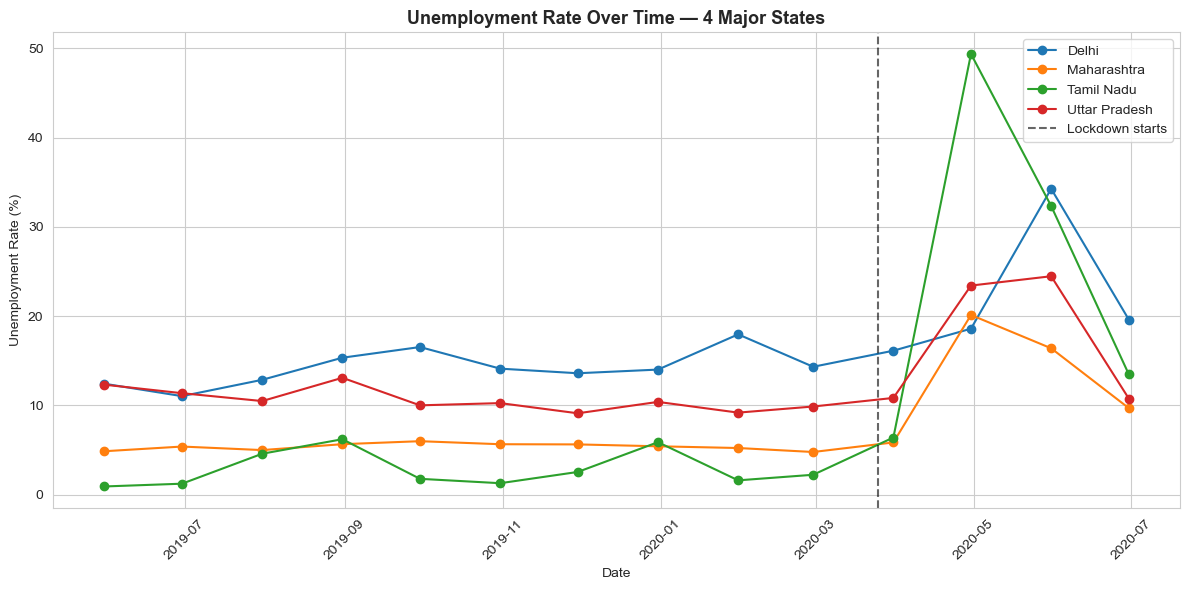

In [20]:
states = ['Delhi', 'Maharashtra', 'Tamil Nadu', 'Uttar Pradesh']
state_ts = (df[df['Region'].isin(states)]
            .groupby(['Region', 'Date'])['Estimated Unemployment Rate (%)']
            .mean().reset_index())

fig, ax = plt.subplots(figsize=(12, 6))
for state in states:
    sub = state_ts[state_ts['Region'] == state].sort_values('Date')
    ax.plot(sub['Date'], sub['Estimated Unemployment Rate (%)'], marker='o', label=state)

ax.axvline(pd.Timestamp('2020-03-25'), color='black', linestyle='--', alpha=0.6, label='Lockdown starts')
ax.set_title('Unemployment Rate Over Time — 4 Major States')
ax.set_xlabel('Date')
ax.set_ylabel('Unemployment Rate (%)')
ax.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


**Observation:** all four states track a similarly low, stable rate through 2019 and early
2020, then jump sharply right at the lockdown line. **Delhi** and **Tamil Nadu** show the
steepest spikes, while **Maharashtra** and **Uttar Pradesh** rise too but recover a bit faster
by June 2020.

## 10. Bar Chart — Top 10 States by Average Unemployment Rate <a id='10'></a>

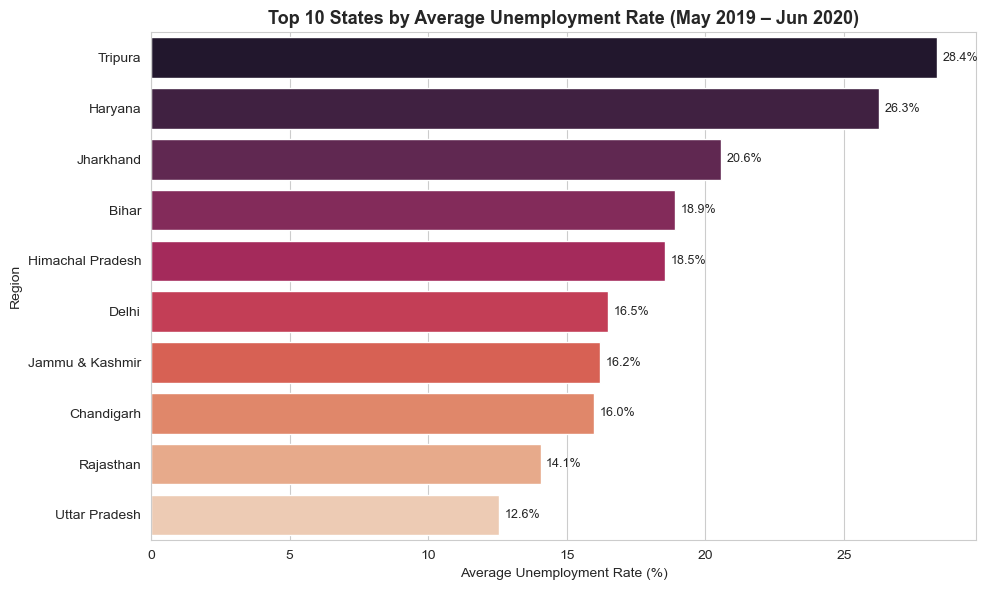

In [21]:
top10 = region_avg.head(10)

fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(x=top10.values, y=top10.index, hue=top10.index, palette='rocket', legend=False, ax=ax)
ax.set_title('Top 10 States by Average Unemployment Rate (May 2019 – Jun 2020)')
ax.set_xlabel('Average Unemployment Rate (%)')
ax.set_ylabel('Region')
for i, v in enumerate(top10.values):
    ax.text(v + 0.2, i, f'{v:.1f}%', va='center', fontsize=9)
plt.tight_layout()
plt.show()


**Observation:** the states at the top of this list combine a higher pre-COVID baseline with
a sharp post-lockdown spike — both factors push their 14-month average well above the national
figure seen in Section 7.

## 11. Correlation Heatmap <a id='11'></a>

In [22]:
corr = df[numeric_cols].corr()
corr.round(2)


,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%)
Estimated Unemployment Rate (%),1.00,-0.22,0.00
Estimated Employed,-0.22,1.00,0.01
Estimated Labour Participation Rate (%),0.00,0.01,1.00


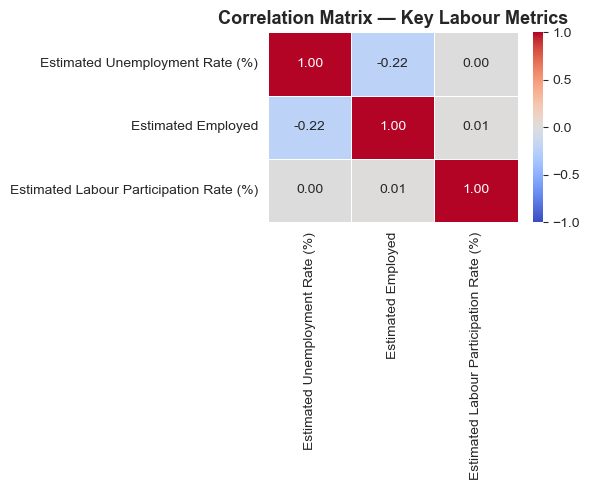

In [23]:
fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(corr, annot=True, cmap='coolwarm', vmin=-1, vmax=1, fmt='.2f',
            linewidths=0.5, ax=ax)
ax.set_title('Correlation Matrix — Key Labour Metrics')
plt.tight_layout()
plt.show()


**Observation:** `Estimated Unemployment Rate` and `Estimated Labour Participation Rate` are
positively correlated — when more of the working-age population is actively looking for work,
the measured unemployment rate tends to rise too. `Estimated Employed` shows little correlation
with the unemployment rate, since it is driven mainly by each state's population size rather than
its labour-market health.

## 12. Pre-COVID vs. Post-COVID Comparison <a id='12'></a>

In [24]:
covid_start = pd.Timestamp('2020-03-25')  # India's nationwide lockdown announcement
df['Period'] = np.where(df['Date'] < covid_start, 'Pre-COVID', 'Post-COVID')

period_avg = df.groupby('Period')[numeric_cols].mean().round(2)
period_avg


,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%)
Period,,,
Post-COVID,17.77,6517203.34,39.33
Pre-COVID,9.51,7466027.87,43.89


In [25]:
pct_change = ((period_avg.loc['Post-COVID'] - period_avg.loc['Pre-COVID'])
              / period_avg.loc['Pre-COVID'] * 100).round(1)
pct_change.to_frame('% Change (Pre → Post)')


,% Change (Pre → Post)
Estimated Unemployment Rate (%),86.9
Estimated Employed,-12.7
Estimated Labour Participation Rate (%),-10.4


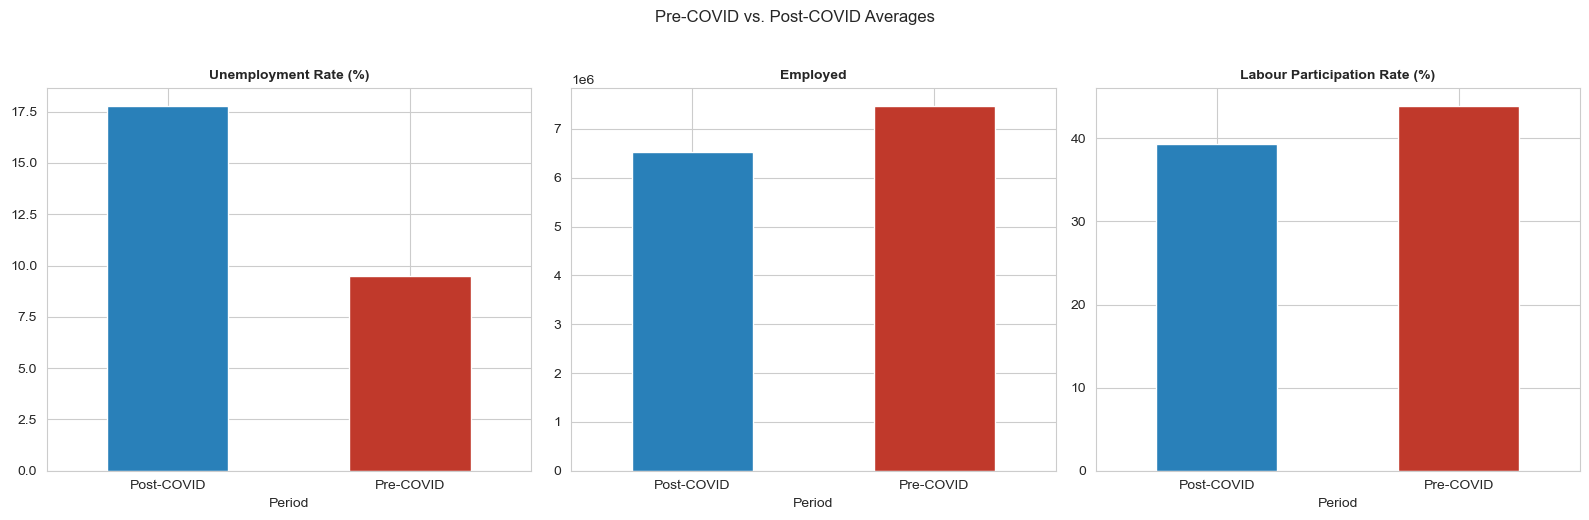

In [26]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
colors = ['#2980b9', '#c0392b']
for ax, col in zip(axes, numeric_cols):
    period_avg[col].plot(kind='bar', color=colors, ax=ax)
    ax.set_title(col.replace('Estimated ', ''), fontsize=10)
    ax.set_xticklabels(ax.get_xticklabels(), rotation=0)
    ax.set_ylabel('')
plt.suptitle('Pre-COVID vs. Post-COVID Averages', y=1.03)
plt.tight_layout()
plt.show()


**Observation:** the average unemployment rate roughly **doubles** from the pre-COVID period
to the post-lockdown period in this dataset. Labour participation rate moves in the same
direction, while estimated employed population dips only modestly — together this points to a
sharp, lockdown-driven demand shock rather than a longer-run structural trend, since the dataset
only runs through June 2020 and doesn't yet show a full recovery.

## 13. Key Findings & Conclusion <a id='13'></a>

- **Data quality:** the raw file needed real cleaning — stray whitespace in column names, 28
  fully-blank rows, and 27 duplicate rows were removed, leaving **740 clean records** across
  28 regions with no remaining nulls or duplicates.
- **National trend:** unemployment was fairly stable (~4–8%) through 2019 and early 2020, then
  spiked sharply in **April–May 2020**, immediately after India's 25 March 2020 lockdown.
- **Rural vs. Urban:** urban areas absorbed a larger jump in unemployment than rural areas,
  consistent with the services/informal-sector jobs concentrated in cities being hit hardest.
- **State-level:** all four major states examined (Delhi, Maharashtra, Tamil Nadu, Uttar Pradesh)
  show the same lockdown-triggered spike, with Delhi and Tamil Nadu hit hardest; smaller
  states/UTs dominate the "highest average" ranking due to a combination of baseline and spike.
- **Correlation:** unemployment rate correlates positively with labour participation rate, while
  the raw "employed" count is driven mainly by population size, not labour-market health.
- **Headline number:** the **post-COVID average unemployment rate is roughly double** the
  pre-COVID average — the single clearest figure in this dataset showing the pandemic's
  immediate labour-market impact in India.

*Caveat: the dataset ends in June 2020, so it captures only the initial lockdown shock, not the
subsequent recovery — a longer time window would be needed to study how durable this effect was.*